In [1]:
%%time
%%capture captured_output
%pip install numpy==1.26 matplotlib==3.9.2 pandas==2.2.3

CPU times: user 4.54 ms, sys: 7.76 ms, total: 12.3 ms
Wall time: 743 ms


In [2]:
def captured_data(captured_txt, lines):

    """ Check the last lines for captured for errors. """

    captured_stdout = captured_txt.stdout
    captured_split = captured_stdout.splitlines()
    captured_error = '\n'.join(captured_split[-lines:])
    print(f'{captured_error}\n')

    if 'error' in captured_error.lower():
        print(f'Error -> \n{captured_error}\n')
    else:
        print(f"No errors -> \n{captured_error}")

captured_data(captured_txt=captured_output, lines=2)

Note: you may need to restart the kernel to use updated packages.

No errors -> 
Note: you may need to restart the kernel to use updated packages.


In [3]:
%%time
%pip install torch==2.8.0+cpu torchvision==0.23.0+cpu torchaudio==2.8.0+cpu \
    --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.
CPU times: user 7 ms, sys: 7.59 ms, total: 14.6 ms
Wall time: 702 ms


In [4]:
import os
import torch
import httpx
from PIL import Image
import skillsnetwork
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import asyncio
import tarfile
from torchvision import transforms, datasets
import numpy as np
from PIL import UnidentifiedImageError



In [5]:
tar_dir = './'
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/4Z1fwRR295-1O3PMQBH6Dg/images-dataSAT.tar"

In [6]:
def precheck(root_dir):
    """ Path verification """
    
    try:
        sym_test = os.path.join(root_dir, 'test')
        if not os.path.exists(sym_test):
            os.symlink(os.path.join(os.sep, 'tmp'), sym_test)
            os.remove(sym_test)
            print('Success, ready for download.')
            return True
        else:
            print('Test path already exists')
            return False

    except OSError as ose:
        print(f"Error -> \n{ose}")
        return False

    except Exception as e:
        print(f"Error -> \n{e}")
        return False

In [7]:
async def manual_download(url, path, dir_path):
    if not os.path.exists(path):
        try:
            print(f'Download -> {url}')
            async with httpx.AsyncClient() as client:
                response = await client.get(url, follow_redirects=True)
                response.raise_for_status()

                with open(path, 'wb') as f:
                    f.write(response.content)
                    print('Download complete for use.')

        except httpx.HTTPStatusError as e:
            print(f"Download failed -> \n{e}")
            return False

        except Exception as e:
            print(f"Error -> \n{e}")
            return False
    else:
        print('Path exists.')

    with tarfile.open(path, 'r:*') as t:
        t.extractall(path=dir_path)
    return True


In [8]:
try:
    if precheck(root_dir=tar_dir):
        await skillsnetwork.prepare(url=url, path=tar_dir, overwrite=True)
        print('skillsnetwork download complete')

except Exception as e:
    print(f"Error, manual function will be used to download. \n{e}") 

    tar_name = Path(url).name
    tar_path = os.path.join(tar_dir, tar_name)
    if await manual_download(url=url, path=tar_path, dir_path=tar_dir):
        print('manual download complete')
    else:
        print('cannot download')

Success, ready for download.


  0%|          | 0/6003 [00:00<?, ?it/s]

Saved to '.'
skillsnetwork download complete


In [9]:
base_dir = os.path.join(tar_dir, 'images_dataSAT')
non_agri_0 = os.path.join(base_dir, 'class_0_non_agri')
agri_one_1 = os.path.join(base_dir, 'class_1_agri')

train_transform = transforms.Compose([transforms.Resize((64, 64)),
                                     transforms.RandomHorizontalFlip(0.5),
                                     transforms.RandomVerticalFlip(0.2),
                                     transforms.RandomRotation(45),
                                     transforms.ToTensor(), # Converts PIL Image to a tensor and scales values to [0, 1]
                                     transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [0.5, 0.5, 0.5]) # Normalize to [-1, 1]
])


In [10]:
class CustomBinaryClassDataset(Dataset):
    def __init__(self, non_agri, agri_one, transform=train_transform):
        self.transform = transform
        self.img_files = []
        self.labels = []

        try:
            for folder, pos in [(non_agri, 0), (agri_one, 1)]:
                for i in os.listdir(folder):
                    self.img_files.append(os.path.join(folder, i))
                    self.labels.append(pos)

        except PermissionError as e:
            print(f"Permission denied -> {e}")
            raise

        except NotADirectoryError as e:
            print(f"Not a directory -> {e}")
            raise

        except FileNotFoundError as e:
            print(f"File not found -> {e}")
            raise

        try:
            temp = list(zip(self.img_files, self.labels))
            np.random.shuffle(temp)
            self.img_files, self.labels = zip(*temp)
            
        except ValueError as e:
            print(f"Value error -> {e}")
            raise

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, pos):
        try:
            img = Image.open(self.img_files[pos]).convert('RGB')
       
            label = self.labels[pos]

            if self.transform:
                img = self.transform(img)
                
        except UnidentifiedImageError as e:
            print(f"Check type -> {e}")
            raise 
        except OSError as e:
            print(f"Error -> {e}")
            raise

        return img, label

base_dir = os.path.join(tar_dir, 'images_dataSAT')
non_agri_0 = os.path.join(base_dir, 'class_0_non_agri')
agri_one_1 = os.path.join(base_dir, 'class_1_agri')





In [11]:


my_dataset = CustomBinaryClassDataset(
    non_agri=non_agri_0, agri_one=agri_one_1, transform=train_transform)

img, label = my_dataset[0]



In [12]:
imagefolder_dataset = datasets.ImageFolder(root=base_dir, transform=train_transform)
print(imagefolder_dataset.classes)

['class_0_non_agri', 'class_1_agri']


In [22]:
BATCH_SIZE=8

custom_dataset = CustomBinaryClassDataset(non_agri=non_agri_0, agri_one=agri_one_1)

custom_loader = DataLoader(custom_dataset, batch_size= BATCH_SIZE, shuffle=True, num_workers=2)

imagefolder_loader = DataLoader(imagefolder_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

img, label = next(iter(custom_loader))



In [ ]:

images_custom, labels_custom = next(iter(custom_loader))



tensor(0.) tensor(1.)


In [ ]:
images_built, labels_inbuilt = next(iter(imagefolder_loader))



torch.Size([8, 3, 64, 64])
torch.Size([8])


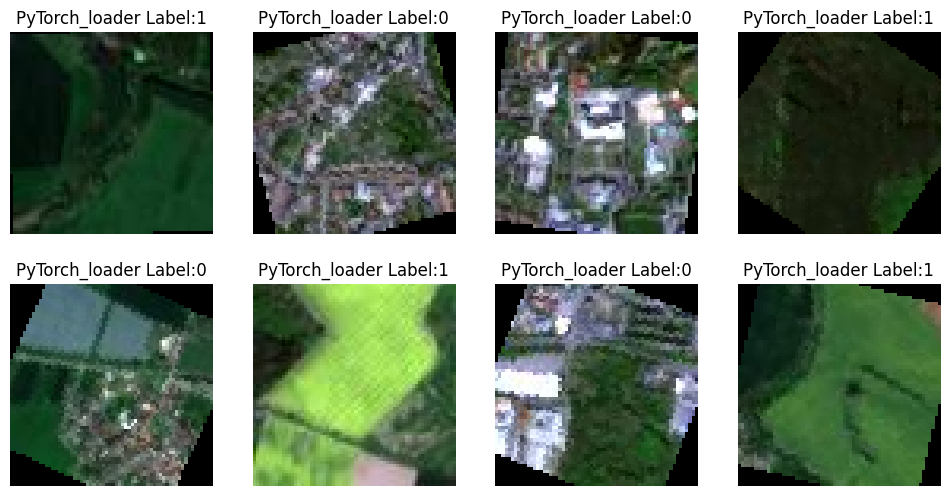

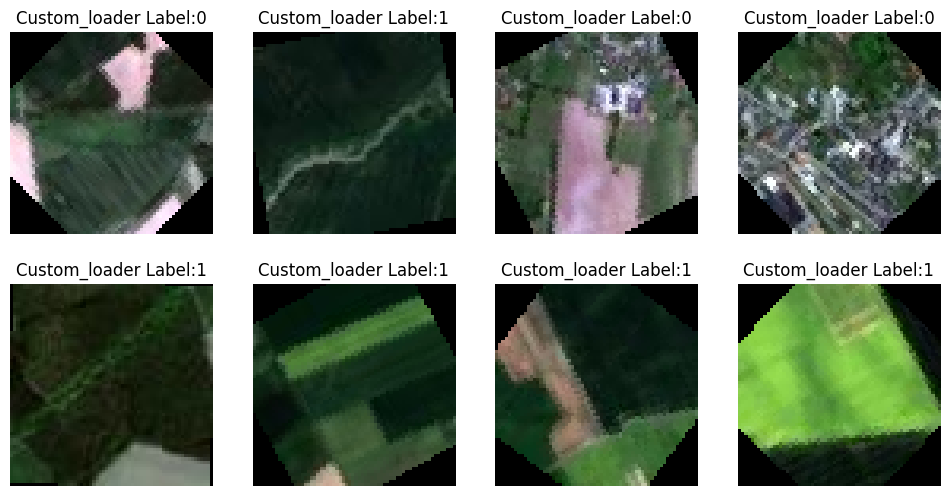

In [54]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1,2,0)))

plt.figure(figsize = (12, 6))
for i in range(BATCH_SIZE):
    ax = plt.subplot(2, 4, i + 1)
    imshow(images_built[i])
    plt.title(f"PyTorch_loader Label:{labels_inbuilt[i].item()}")
    plt.axis("off")

plt.figure(figsize=(12, 6))
for i in range(BATCH_SIZE):
    ax = plt.subplot(2, 4, i + 1)
    imshow(images_custom[i])
    plt.title(f"Custom_loader Label:{labels_custom[i].item()}")
    plt.axis("off")